SciPy provides algorithms for optimization, integration, interpolation, eigenvalue problems, algebraic equations, differential equations, statistics and many other classes of problems. It extends NumPy providing additional tools for array computing and provides specialized data structures, such as sparse matrices and k-dimensional trees.

SciPy is organized into subpackages covering different scientific computing domains. We will cover only small number of them here:
- `linalg`
- `stats`

In [ ]:
import os
import numpy as np
import pandas as pd

from scipy import linalg
from scipy import stats

import statsmodels.api as sm
from statsmodels.formula.api import ols

In [ ]:
os.chdir("..\\data")

# Linear Algebra

`scipy.linalg` contains all the functions in `numpy.linalg`, plus some other more advanced ones not contained in `numpy.linalg`.

<div class="alert alert-block alert-warning">
<b>Example: </b> Calculate determinant and inverse of matrix $A$ given below. Check if the dot product of the matrix with its inverse is unit matrix.
</div>

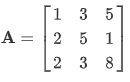

In [ ]:
a = np.array([[1., 3., 5.], [2., 5., 1.], [2., 3., 8.]])
a

In [ ]:
a_det = linalg.det(a)
a_det

In [ ]:
a_inv = linalg.inv(a)
a_inv

In [ ]:
print('a x a_inv =', np.dot(a, a_inv))

It doesn't look like unit matrix $I$, but if you were to round your results, you would get $I$.

In [ ]:
np.abs(np.round(np.dot(a, a_inv)))

<div class="alert alert-block alert-danger">
<b></b>Computing the inverse of a singularmatrix (its determinant is zero) will raise LinAlgError.
</div>


You SHOULD get LinAlgError error in the cell output below:

In [ ]:
b = np.array([[3, 2],[6, 4]])
linalg.inv(b)

<div class="alert alert-block alert-warning">
<b>Example: </b> Calculate $L_1$ and $L_{inf}$ norms for the matrix $A$ from the previous example.
</div>

In [ ]:
linalg.norm(a, 1) # L1 norm (max column sum)

In [ ]:
linalg.norm(a, np.inf) # L inf norm (max row sum)

<div class="alert alert-block alert-warning">
<b>Example: </b> Fit a quadratic polynomial of the form $y = a + b x^2$, for the given $x$ and $y$.
</div>

Create random vectors $x$ and $y$: 

In [ ]:
y = np.random.random(10)
x = np.random.random(10)

We first form the "design matrix" M, with a constant column of 1s and a column containing $x^2$. NumPy array $x$ is reshaped from 1-D (row vector) to 2-D with size of the second dimension 1 (column vector) with `x[:, np.newaxis]`.

In [ ]:
M = x[:, np.newaxis]**[0, 2]
M

Then, the system Mc = y is solved using `lstsq()` function:

In [ ]:
c, res, rnk, s = linalg.lstsq(M, y)
c

In [ ]:
print('Quadratic polynomial coefficients:')
print('a =', c[0])
print('b =', c[1])

<div class="alert alert-block alert-info">
<b>Tip: </b><code>scipy.linalg</code> provides common decomposition methods (SVD, LU, QR etc.). Learn more <a href="https://docs.scipy.org/doc/scipy/tutorial/linalg.html#decompositions">here</a>.
</div>

# Statistics

![Normal distribution meme](../imgs/nd2.jpg)

## Random variables

Over 80 continuous random variables and 10 discrete have been implemented in `scipy.stats`, with corresponding methods. The most useful methods for continuous random variables are:

- `rvs()`: Random Variates (allows to draw a random number of values from a distribution.)
- `pdf()`: Probability Density Function
- `cdf()`: Cumulative Distribution Function

Let’s take a normal RV as an example. The following line will provide random variate from a Gaussian distribution in the standardized form with size 900.

In [ ]:
data = stats.norm.rvs(size=900) 
data[:10]

For a normal variate that has not been standardized, `loc` keyword specifies the mean and `scale` keyword specifies the standard deviation.

In [ ]:
data = stats.norm.rvs(loc = 1, scale=0.5, size=1000)
data[:10]

## Statistical testing - Numerical variables

Let's start with a practical example: Are the means of two groups significantly different? Imagine that we want to compare the exam scores of students taught using two different methods, or the average daily temperatures recorded at two locations. We have two samples and want to determine whether the observed difference in their means reflects a genuine difference between the populations or could simply be due to random variation.

The Student’s t-test helps us answer this question by testing whether the means of two groups differ significantly. Before applying the test, however, we need to check whether its assumptions are reasonably satisfied. These include the independence of observations and, for the classical t-test, the assumption that the data in each population are normally distributed. The equal-variance assumption is required for the standard pooled Student’s t-test, but not for Welch’s t-test, which is often a more flexible alternative.

<div class="alert alert-block alert-warning">
<b>Example: </b>To explore how the t-test works, let's simulate two independent samples drawn from normal distributions. We will start with the same distribution for both groups, meaning that they have the same population mean and standard deviation. This gives us a simple example in which we know there is no true difference between the population means.
</div>

In [ ]:
rvs1 = stats.norm.rvs(loc=5, scale=10, size=500)
rvs2 = stats.norm.rvs(loc=5, scale=10, size=500)

In [ ]:
stats.ttest_ind(rvs1, rvs2) # equal_var=True by default

Since the p-value is greater than the significance level of 0.05, we fail to reject the null hypothesis. There is insufficient statistical evidence to conclude that the mean temperatures differ significantly between the two weeks. However, random sampling can still produce different sample means, and the test may occasionally return a small p-value even when the population means are equal. This is a useful way to see how statistical tests behave in practice.

In [ ]:
stats.ttest_ind(rvs1, rvs2, equal_var=False) # equal_var=False --> Welch's t-test

<div class="alert alert-block alert-warning">
<b>Example: </b>Do the temperatures differ significantly between the two weeks?
</div> 

Lets calculate the t-test on TWO RELATED samples of temperatures, week1 and week2.

The t-statistic is calculated as 

$t = \frac{\operatorname{mean}(week1 - week2)}{SE} $, 

where SE is the standard error. Therefore, the t-statistic will be positive when the sample mean of $(week1 - week2) > 0$ and negative when the sample mean of $(week1 - week2) < 0$.

In [ ]:
# Define your two independent groups: Average daily temperatures
week1 = np.array([18.5, 20.0, 21.5, 19.0, 15.0, 16.5, 17])
week2 = np.array([22.0, 23.5, 24.0, 21.5, 18.0, 17.05, 19])

# Perform Welch's t-test
t_stat, p_value = stats.ttest_rel(week1, week2)
print('T-statistics: ', t_stat)
print('P-value: ', p_value)

While a t-test evaluates the difference between two group means, ANOVA (Analysis of Variance) allows us to investigate how one or more factors influence a variable and whether their effects interact.
The primary difference between a t-test and ANOVA is the number of groups being compared: if two groups then t-test, and if three or more then ANOVA.

In Python, you can use both <code>scipy.stats.ttest_ind()</code> or <code>scipy.stats.f_oneway()</code> to test whether group means differ significantly. 

<div class="alert alert-block alert-warning">
    <b>Example: </b>Import data from <code>mice_data.csv</code>.

Genotypes description:
<ul>
    <li>WT (Wild Type): Carries the naturally occurring, unmodified, and fully functional copy of the gene.</li>
    <li>KO (Knockout): Genetically engineered to permanently inactivate or delete the target</li>
</ul>

Diet description:
<ul>
    <li>HFD (High-Fat Diet): A diet containing a high proportion of calories from fat, commonly used in animal experiments to study obesity, insulin resistance, and metabolic changes.</li>
    <li>CHOW (Standard Chow Diet): A standard laboratory animal diet, typically made from grains and other ingredients, used as a control or reference diet.</li>
</ul>

Answer the questions:
<ol>
    <li>(Diet → Weight) Does the diet change body weight, regardless of whether the mice are WT or KO?</li>
    <li>(Genotype → Weight) Does the knockout itself change body weight, regardless of what the mice eat?</li>
    <li>(Interaction: Diet x Genotype → Weight) Does the KO mouse respond differently to the diet compared to the WT mouse? (e.g., If WT mice gain weight on a high-fat diet, but KO mice stay lean, you have a significant interaction)</li>
</ol>

</div>

In [ ]:
mice_data = pd.read_csv("mice_data.csv")
mice_data.head()

In [ ]:
mice_data['genotype'].unique()

In [ ]:
mice_data['diet'].unique()

1. Diet → Weight

$H_0$ - average weight of mice with different diet are the same

$\alpha = 0.05$

In [ ]:
HFD_data = mice_data[mice_data["diet"] == "HFD"]["weight"]
CHOW_data = mice_data[mice_data["diet"] == "CHOW"]["weight"]
tstat, pval = stats.ttest_ind(HFD_data, CHOW_data, equal_var=False) # Welch's t-test

print("test statistic:", tstat)
print("p-value:", pval)

We reject $H_0$, since $p-value$ is below $0.05$. There is statistically significant evidence that mean body weight differs between diets.

2. Genotype → Weight

$H_0$ - average weight of mice of different genotypes are the same

$\alpha = 0.05$

<div class="alert alert-block alert-success">
    <b>Task: </b>Solve 2.
</div>

In [ ]:
#solution

3. Diet x Genotype → Weight
What if we also want to investigate whether the effect of diet depends on the genotype of the mice? This is where two-way ANOVA becomes useful: it allows us to examine the effects of both diet and genotype, as well as their interaction.

In [ ]:
model = ols('weight ~ C(diet) + C(genotype) + C(diet):C(genotype)', data=mice_data).fit()
anova_result = sm.stats.anova_lm(model, type=2)
anova_result

Because the interaction is not statistically significant ($p > 0.05$), we do not have evidence that the effect of diet on body weight depends on genotype.

*What if our data are not normally distributed?*

So far, we have used t-tests and ANOVA to compare group means. These tests rely on certain assumptions about the data, including the normality of the observations within each group (or, more precisely, the model residuals). But real-world data do not always follow a normal distribution. For example, biological measurements may be strongly skewed, contain outliers, or represent counts rather than continuous measurements. Before choosing a statistical test, we should explore the distribution of our data and check whether the assumptions of our chosen method are reasonable. 

If the normality assumption is not reasonable, we may consider alternative methods. For comparing two independent groups, the Mann–Whitney U test is a common option; for comparing three or more independent groups, we can use the Kruskal–Wallis test, a non-parametric alternative to one-way ANOVA. These tests do not require normally distributed data, although they have their own assumptions and do not always test differences in means.

Let's explore how to check normality and choose an appropriate statistical test using Python.

<div class="alert alert-block alert-warning">
    <b>Example: </b>Compare the body weight of mice fed three different diets. We can create a dataset with three groups: standard chow, high-fat diet (HFD), and low fat diet. To make the exercise meaningful, we can simulate normally distributed weights in two groups and skewed weights in the third. Each row represents one mouse. The diet column indicates its group, and weight records its body weight in grams.
</div>

In [ ]:
np.random.seed(42)
n = 40
df = pd.DataFrame({"diet": ["Chow"] * n + ["HFD"] * n + ["LowFat"] * n,
    "weight": np.concatenate([
        np.random.normal(25, 3, n),       # approximately normal
        np.random.normal(32, 4, n),       # approximately normal
        np.random.lognormal(3.2, 0.35, n))}) # right-skewed

In [ ]:
for diet, group in df.groupby("diet"):
    statistic, pvalue = stats.shapiro(group["weight"])
    print(f"{diet}: p-value = {pvalue:.4f}")

<div class="alert alert-block alert-success">
    <b>Task: </b>Perform appropriate test for group testing.
</div>

In [ ]:
#solution

## Statistical testing - Categorical variables

<div class="alert alert-block alert-warning">
<b>Example: </b>Measure statistical dependence between <i>Crop</i> and <i>Previous crop</i> attributes in <code>database_biosense.csv</code>.
</div>

First import data:

In [ ]:
data = pd.read_csv('database_biosense.csv', sep=';', usecols=(3,6), skiprows=2)
data

Both given attributes are categorical, hence, we need to create a contigency table:

In [ ]:
pt = data.pivot_table(index='Crop', columns='Previous crop', aggfunc=len, fill_value=0)
pt

Then, we can test for the difference between them:

In [ ]:
chi2, p, dof, _ = stats.chi2_contingency(pt) # Chi-square test of independence of variables in a contingency table

`chi2_contingency()` performs chi-square test of independence of variables in a contingency table.

$H_0$ - *Crop* and *Previous crop* attributes are independent

$\alpha = 0.01$

In [ ]:
print("The chi2 test statistic:", chi2)
print("The p-value of the test:", p)
print("Degrees of freedom:", dof)

*Crop* and *Previous crop* attributes are dependent at level confidence 0.01 ($p-value <\alpha=0.01$)